# Toronto Traffic Forecaster 🚗

Predicts how many cars will pass a spot on a Toronto road **15, 30 and 60 minutes ahead**.

**Data:** City of Toronto Open Data, *Traffic Volumes – Midblock Vehicle Speed, Volume and Classification Counts* (15-minute car counts, 2021–2022).

**Approach:** gradient boosting that predicts traffic *relative to the last hour*, tested on streets the model never saw during training.

## 1. Setup

In [1]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

## 2. Download the data

Asks Toronto's open data API for the dataset, then downloads the 2020–2024 raw volume file into `data/`.
It skips the download if the file is already there.

In [2]:
url = "https://ckan0.cf.opendata.inter.prod-toronto.ca/api/3/action/package_show"
params = {"id": "traffic-volumes-midblock-vehicle-speed-volume-and-classification-counts"}
package = requests.get(url, params=params).json()["result"]

os.makedirs("data", exist_ok=True)

for resource in package["resources"]:
    if resource["name"] == "svc_raw_data_volume_2020_2024":
        save_path = os.path.join("data", resource["url"].split("/")[-1])
        if not os.path.exists(save_path):
            with open(save_path, "wb") as f:
                f.write(requests.get(resource["url"]).content)

raw = pd.read_csv(save_path)
print("Rows:", len(raw), "| sessions:", raw["count_id"].nunique(), "| streets:", raw["location_name"].nunique())

Rows: 17568 | sessions: 40 | streets: 27


## 3. Build features

Each row is one 15-minute chunk at one spot, in one direction.

- **Time clues:** `hour` (9:45am → 9.75), `day_of_week` (0 = Monday), `is_weekend`
- **Lag clues:** traffic 15, 30, 45 and 60 minutes ago, shifted *within* each counting session and direction
- **Targets (answers):** traffic 15, 30 and 60 minutes in the future
- Rows with missing clues or answers (the start and end of each session) are dropped

In [3]:
features = ["hour", "day_of_week", "is_weekend", "volume_15min",
            "vol_15min_ago", "vol_30min_ago", "vol_45min_ago", "vol_60min_ago"]
targets = ["target_15min", "target_30min", "target_60min"]

def build_features(data):
    data = data.copy()
    data["time_start"] = pd.to_datetime(data["time_start"])
    data = data.sort_values(["count_id", "direction", "time_start"]).reset_index(drop=True)

    data["hour"] = data["time_start"].dt.hour + data["time_start"].dt.minute / 60
    data["day_of_week"] = data["time_start"].dt.day_of_week
    data["is_weekend"] = (data["day_of_week"] >= 5).astype(int)

    group = data.groupby(["count_id", "direction"])["volume_15min"]
    data["vol_15min_ago"] = group.shift(1)
    data["vol_30min_ago"] = group.shift(2)
    data["vol_45min_ago"] = group.shift(3)
    data["vol_60min_ago"] = group.shift(4)
    data["target_15min"] = group.shift(-1)
    data["target_30min"] = group.shift(-2)
    data["target_60min"] = group.shift(-4)

    return data.dropna(subset=features + targets)

clean = build_features(raw)
print("Rows ready:", len(clean))

Rows ready: 17128


## 4. Look at the data

One full week on one street, in both directions. You can see the daily rush hours, the quiet nights and the lighter weekend.

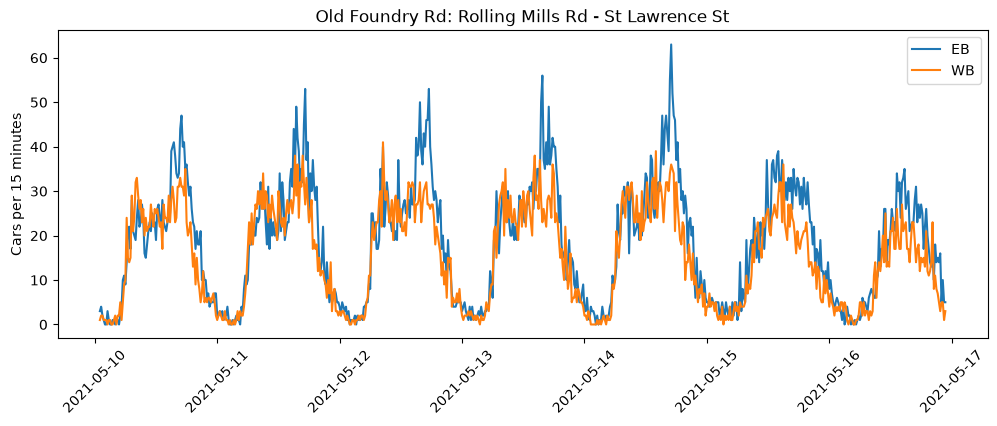

In [4]:
busiest_session = clean.groupby("count_id").size().idxmax()
one = clean[clean["count_id"] == busiest_session]

plt.figure(figsize=(12, 4))
for direction in one["direction"].unique():
    part = one[one["direction"] == direction]
    plt.plot(part["time_start"], part["volume_15min"], label=direction)
plt.title(one["location_name"].iloc[0])
plt.ylabel("Cars per 15 minutes")
plt.legend()
plt.xticks(rotation=45)
plt.show()

## 5. Split by street

6 random streets are held out as the **test set**. Every week counted on those streets goes into the test set, so the model is graded only on roads it has never seen.

(Splitting by counting session instead would leak: some streets were counted in more than one week.)

In [5]:
streets = clean["location_name"].unique()
rng = np.random.default_rng(42)
test_streets = rng.choice(streets, size=6, replace=False)

test = clean[clean["location_name"].isin(test_streets)]
train = clean[~clean["location_name"].isin(test_streets)]

print("Train rows:", len(train), "| streets:", train["location_name"].nunique())
print("Test rows: ", len(test), "| streets:", test["location_name"].nunique())
print()
print("Test streets:")
for street in sorted(test_streets):
    print(" -", street)

Train rows: 12528 | streets: 21
Test rows:  4600 | streets: 6

Test streets:
 - Dewson St: Rusholme Rd - Havelock St
 - Don Valley Parkway N (id: 30106222)
 - Don Valley Parkway S (id: 2917728)
 - Hepbourne St: Rusholme Rd - Havelock St
 - Lindsey Ave: Havelock St - Gladstone Ave
 - St Lawrence St: Trolley Cres - King St E


## 6. Relative features

Roads range from quiet side streets (~5 cars per 15 min) to the DVP (~180).
So instead of raw car counts, every traffic number is divided by that street's **average over the last hour** (`recent_avg`).
The model learns *"traffic will be 20% higher than the last hour"*, which works on any size of road.
Its guesses are multiplied by `recent_avg` to turn them back into car counts.

In [6]:
lag_cols = ["volume_15min", "vol_15min_ago", "vol_30min_ago", "vol_45min_ago", "vol_60min_ago"]

def add_relative(data):
    data = data.copy()
    data["recent_avg"] = data[lag_cols[:4]].mean(axis=1) + 1
    for col in lag_cols:
        data["rel_" + col] = data[col] / data["recent_avg"]
    return data

train_r = add_relative(train)
test_r = add_relative(test)
rel_features = ["hour", "day_of_week", "is_weekend"] + ["rel_" + col for col in lag_cols]

## 7. Train and score

One model per horizon, compared against the **lazy guess** baseline ("traffic stays the same as right now").
The score is **MAE**, the average number of cars the guess is off by. Lower is better.

In [7]:
models = {}
results = []

for target in targets:
    lazy = (test[target] - test["volume_15min"]).abs().mean()

    model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)
    model.fit(train_r[rel_features], train_r[target] / train_r["recent_avg"])
    models[target] = model

    guesses = model.predict(test_r[rel_features]) * test_r["recent_avg"]
    error = (test[target] - guesses).abs().mean()
    results.append({"horizon": target.replace("target_", ""),
                    "lazy guess MAE": round(lazy, 2),
                    "model MAE": round(error, 2),
                    "improvement": f"{(1 - error / lazy) * 100:.0f}%"})

pd.DataFrame(results)

,horizon,lazy guess MAE,model MAE,improvement
0,15min,5.13,4.88,5%
1,30min,5.99,5.56,7%
2,60min,7.33,6.53,11%


## 8. Forecast chart

The 60-minute model's guesses vs. what really happened, on a test street it never studied (the DVP if it's in the test set).
Each guess is plotted at the time it was predicting, so a guess made at 3:00pm appears at 4:00pm.

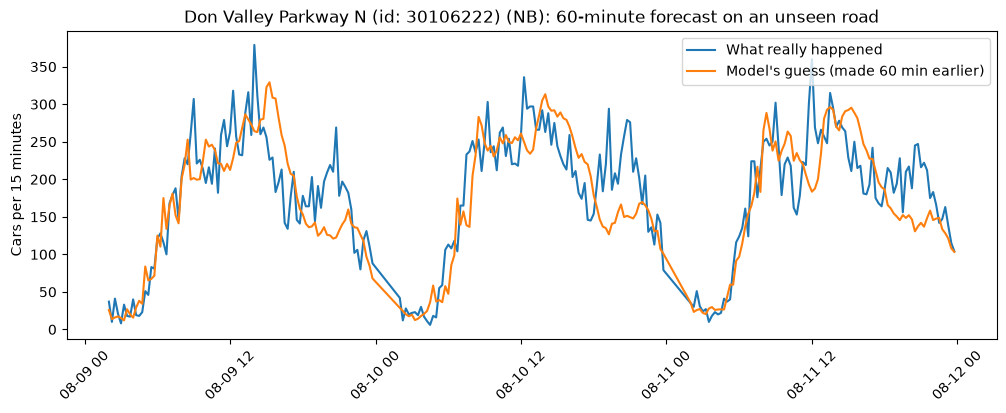

In [8]:
dvp = [s for s in test_streets if "Don Valley" in s]
chart_street = dvp[0] if dvp else test_streets[0]

one_way = test_r[test_r["location_name"] == chart_street]
one_way = one_way[one_way["direction"] == one_way["direction"].iloc[0]].sort_values("time_start")

guesses = models["target_60min"].predict(one_way[rel_features]) * one_way["recent_avg"]
future_time = one_way["time_start"] + pd.Timedelta(minutes=60)

plt.figure(figsize=(12, 4))
plt.plot(future_time, one_way["target_60min"], label="What really happened")
plt.plot(future_time, guesses, label="Model's guess (made 60 min earlier)")
plt.title(f"{chart_street} ({one_way['direction'].iloc[0]}): 60-minute forecast on an unseen road")
plt.ylabel("Cars per 15 minutes")
plt.legend()
plt.xticks(rotation=45)
plt.savefig("forecast.png", dpi=150, bbox_inches="tight")
plt.show()

## What I learned

- **Splitting by session leaked.** Some streets were counted in more than one week, so they showed up in both training and test. With an honest split by street, the first model did *worse* than the lazy guess.
- **Relative features fixed it.** Predicting change compared to the last hour, instead of raw car counts, made the model work on roads of very different sizes.
- **More data made it worse.** Adding 2015–2019 data (30× more rows, all clean, with no gaps) hurt the score on the 2021–2022 test streets, most likely because pre-COVID traffic patterns didn't match. The test set is small (6 streets), so this is a likely explanation, not a proven one.